# Chapter 2 notebook: waves, interfaces, and sheets

**Predict first:** can a field ratio of 0.8 transmit 96% of the incident power?
Can a field exist in a medium while its net normal power is zero? Can adding
an interface remove reflection? Can relative phase change absorption?

This notebook answers those questions using **exact planar analytical models**.
It does not discretize a patterned metasurface or run a full-wave geometry solver.
Bulk media have positive real constant indices and are nonmagnetic and isotropic.
The electric sheet may dissipate power through nonnegative conductance.
Use $e^{-i\omega t}$ and $e^{+i\mathbf k\cdot\mathbf r}$ throughout.

Topic IDs: `ms-01-waves-interfaces`, introductory `ms-03-sheet-response`,
and the Jones-vector baseline of `ms-06-polarization`.

In [1]:
from pathlib import Path
import sys,json,csv,hashlib,platform,html
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display,HTML
ROOT=next((p for p in [Path.cwd(),*list(Path.cwd().parents)[:3]] if (p/'simulations/waves_interfaces.py').is_file()),None)
if ROOT is None:raise FileNotFoundError('Extract the complete Chapter 2 ZIP, preserving simulations/, notebooks/, and data/.')
sys.path.insert(0,str(ROOT/'simulations'))
from waves_interfaces import (interface,film,film_scattering,sheet,sheet_scattering,
                             coherent_sheet,retrieve_sheet,polarization,te_interface_fields,MODEL_VERSION)

# Editable reference experiment. Indices are ideal real constants, not measured dispersion.
N_INCIDENT=1.;N_OUTPUT=1.5;WAVELENGTH_UM=.6
N_FILM=np.sqrt(N_INCIDENT*N_OUTPUT)
from source_provenance import notebook_code_sha256, json_sha256, result_sha256
NOTEBOOK_PATH=ROOT/'notebooks/02-waves-and-interfaces.ipynb'
CODE_SHA256=notebook_code_sha256(NOTEBOOK_PATH)  # Save edits before Restart/Run All.
THICKNESS_UM=WAVELENGTH_UM/(4*N_FILM)
FIELD_N1=1.5;FIELD_N2=1.;FIELD_ANGLE_DEG=50.
JONES_ALPHA_DEG=45.  # The plot compares relative phases 0, 45, and 90 degrees.
SHEET_G=2.;SHEET_B=0.
ANGLES_DEG=np.linspace(0.,85.,341)
DATA=ROOT/'data/chapter-02';DATA.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'figure.dpi':125,'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
TEAL='#087f8c';ORANGE='#d48026';NAVY='#193d57';PURPLE='#8064a2'
def table(headers,rows):
    def esc(x):return html.escape(f'{x:.7g}' if isinstance(x,(float,np.floating)) else str(x))
    display(HTML('<table><thead><tr>'+''.join('<th>'+esc(x)+'</th>' for x in headers)+'</tr></thead><tbody>'+''.join('<tr>'+''.join('<td>'+esc(x)+'</td>' for x in row)+'</tr>' for row in rows)+'</tbody></table>'))
def ctext(z):return f'{complex(z).real:.5f}{complex(z).imag:+.5f}i'
table(['Parameter','Value'],[['n incident/output',f'{N_INCIDENT:g} / {N_OUTPUT:g}'],['Wavelength (um)',WAVELENGTH_UM],['Film index',N_FILM],['Film thickness (um)',THICKNESS_UM],['Time convention','exp(-i omega t)'],['Model version',MODEL_VERSION]])
print('Environment:',platform.python_version(),'NumPy',np.__version__,'Matplotlib',matplotlib.__version__)

Parameter,Value
n incident/output,1 / 1.5
Wavelength (um),0.6
Film index,1.224745
Film thickness (um),0.1224745
Time convention,exp(-i omega t)
Model version,waves-interfaces-1.0


Environment: 3.12.1 NumPy 2.4.6 Matplotlib 3.11.1


## 1. Amplitude and power

At $z=0$ use the same tangential electric-field axis for incident, reflected,
and transmitted coefficients. Thus $t=1+r$ at a dielectric interface.
Use dimensionless $Y_j=q_j$ for TE and $Y_j=n_j^2/q_j$ for TM.
The physical wave admittance is $Y_j/\eta_0$, where
$q_j=\sqrt{n_j^2-n_1^2\sin^2\theta_i}$ has the outgoing/decaying branch.

$$
r=\frac{Y_1-Y_2}{Y_1+Y_2},\quad t=\frac{2Y_1}{Y_1+Y_2},\quad
R=|r|^2,\quad T=\frac{\operatorname{Re}Y_2}{Y_1}|t|^2.
$$

The reflected TM coefficient has a sign difference from a convention using a
rotated local p basis. At normal incidence both tangential-basis coefficients
are $r=-0.2$, $t=0.8$ for air/glass, giving $R=0.04$, $T=0.96$.
Predict the Brewster zero and the glass-to-air critical angle before plotting.

Case,r (tangential E),t (tangential E),R,T,Regime
normal TE,-0.20000+0.00000i,0.80000+0.00000i,0.04,0.96,propagating
normal TM,-0.20000+0.00000i,0.80000+0.00000i,0.04,0.96,propagating
Brewster TM,0.00000+0.00000i,1.00000+0.00000i,0,1,propagating
Edited field TE,0.48743-0.87316i,1.48743-0.87316i,1,0,evanescent
Edited field TM,0.27128+0.96250i,1.27128+0.96250i,1,0,evanescent


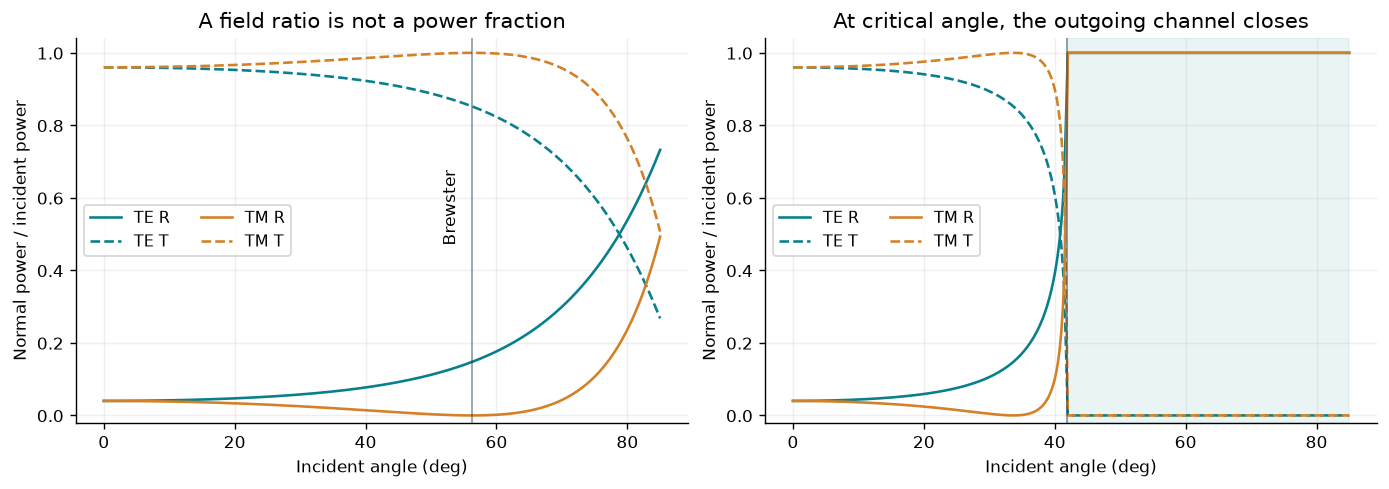

In [2]:
theta_b=float(np.rad2deg(np.arctan(N_OUTPUT/N_INCIDENT)))
theta_c=float(np.rad2deg(np.arcsin(FIELD_N2/FIELD_N1))) if FIELD_N1>FIELD_N2 else None
interface_cases=[];angular={}
for name,n1,n2,angle,pol in [('normal TE',N_INCIDENT,N_OUTPUT,0.,'TE'),('normal TM',N_INCIDENT,N_OUTPUT,0.,'TM'),('Brewster TM',N_INCIDENT,N_OUTPUT,theta_b,'TM'),('Edited field TE',FIELD_N1,FIELD_N2,FIELD_ANGLE_DEG,'TE'),('Edited field TM',FIELD_N1,FIELD_N2,FIELD_ANGLE_DEG,'TM')]:
    v=interface(n1,n2,angle,pol)
    interface_cases.append(dict(name=name,parameters=dict(n1=n1,n2=n2,angle_deg=angle,polarization=pol),response=v))
table(['Case','r (tangential E)','t (tangential E)','R','T','Regime'],[[c['name'],ctext(c['response']['r']),ctext(c['response']['t']),float(c['response']['R']),float(c['response']['T']),str(c['response']['regime'])] for c in interface_cases])
fig,axes=plt.subplots(1,2,figsize=(11,3.8),layout='constrained')
for ax,name,n1,n2 in [(axes[0],'air_to_glass',N_INCIDENT,N_OUTPUT),(axes[1],'glass_to_air',FIELD_N1,FIELD_N2)]:
    for pol,color in [('TE',TEAL),('TM',ORANGE)]:
        v=interface(n1,n2,ANGLES_DEG,pol);angular[name+'_'+pol]=v
        ax.plot(ANGLES_DEG,v['R'],color=color,label=pol+' R')
        ax.plot(ANGLES_DEG,v['T'],'--',color=color,label=pol+' T')
    ax.set(xlabel='Incident angle (deg)',ylabel='Normal power / incident power',ylim=(-.02,1.04))
    ax.grid(alpha=.2);ax.legend(ncol=2,fontsize=9)
axes[0].set_title('A field ratio is not a power fraction')
axes[0].axvline(theta_b,color=NAVY,lw=1,alpha=.5);axes[0].text(theta_b-2,.48,'Brewster',rotation=90,ha='right')
axes[1].set_title('At critical angle, the outgoing channel closes')
if theta_c is not None:axes[1].axvspan(theta_c,85,color=TEAL,alpha=.08);axes[1].axvline(theta_c,color=NAVY,lw=1,alpha=.5)
plt.show()

## 2. Evanescent fields

For glass to air beyond the critical angle, $k_{z,2}=i\kappa$ and
$E_t\propto e^{ik_xx}e^{-\kappa z}$. Its nonzero field is not a propagating
normal power channel. We reconstruct $E_y$ and $H_x$ and calculate
$S_z=-\tfrac12\operatorname{Re}(E_yH_x^*)$ directly.

At exact cutoff, TE has tangential $t\to2$; TM has tangential $t\to0$.
Both give $T=0$. The latter does not imply that the longitudinal TM field
$E_z$ vanishes. Undefined phase at zero tangential amplitude is kept separate
from zero normal flux of a nonzero evanescent field.

The default field is evanescent. Changing the angle can produce a propagating or grazing field: the labels and checks follow that regime and compare reconstructed normal flux with the Fresnel power.


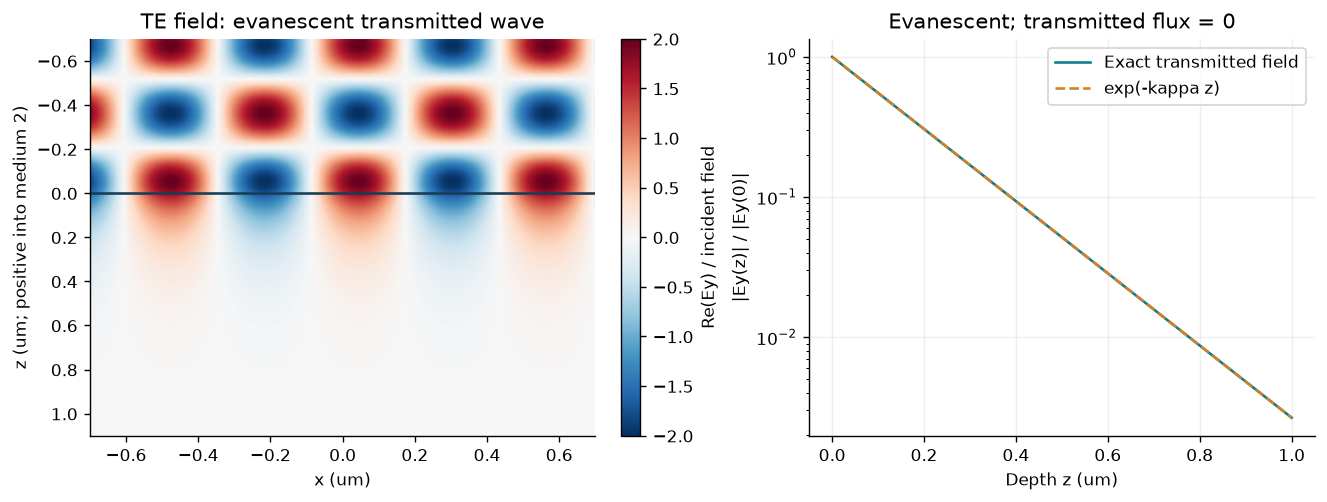

Edited TE field quantity,Value
max_incident_region_flux_error,7.447406e-16
max_transmitted_flux,1.610571e-16
transmitted_amplitude,1.72478
regime,evanescent
max_transmitted_flux_error,1.610571e-16


In [3]:
x=np.linspace(-.7,.7,281);z=np.linspace(-.7,1.1,361)
X,Z=np.meshgrid(x,z)
field=te_interface_fields(X,Z,FIELD_N1,FIELD_N2,FIELD_ANGLE_DEG,WAVELENGTH_UM)
v=interface(FIELD_N1,FIELD_N2,FIELD_ANGLE_DEG,'TE')
regime='evanescent' if v['q2'].imag>0 else 'grazing' if v['q2'].real==0 else 'propagating'
depth=np.linspace(0.,1.,201)
decay=te_interface_fields(np.zeros_like(depth),depth,FIELD_N1,FIELD_N2,FIELD_ANGLE_DEG,WAVELENGTH_UM)
fig,axes=plt.subplots(1,2,figsize=(10.5,3.9),layout='constrained')
im=axes[0].imshow(field['E'].real,extent=[x.min(),x.max(),z.max(),z.min()],origin='upper',aspect='auto',cmap='RdBu_r',vmin=-2,vmax=2)
axes[0].axhline(0,color=NAVY,lw=1.5);axes[0].set(xlabel='x (um)',ylabel='z (um; positive into medium 2)',title=f'TE field: {regime} transmitted wave')
fig.colorbar(im,ax=axes[0],label='Re(Ey) / incident field')
axes[1].semilogy(depth,np.abs(decay['E'])/abs(v['t']),color=TEAL,label='Exact transmitted field')
axes[1].semilogy(depth,np.exp(-2*np.pi/WAVELENGTH_UM*v['q2'].imag*depth),'--',color=ORANGE,label='exp(-kappa z)')
axes[1].set(xlabel='Depth z (um)',ylabel='|Ey(z)| / |Ey(0)|',title=f'{regime.capitalize()}; transmitted flux = {float(v["T"]):.3g}');axes[1].grid(alpha=.2);axes[1].legend()
plt.show()
field_checks=dict(max_incident_region_flux_error=float(np.max(abs(field['normal_flux'][Z<0]-v['T']))),max_transmitted_flux=float(np.max(abs(field['normal_flux'][Z>=0]))),transmitted_amplitude=float(abs(v['t'])))
field_checks['regime']=regime
field_checks['max_transmitted_flux_error']=float(np.max(abs(field['normal_flux'][Z>=0]-v['T'])))
table(['Edited TE field quantity','Value'],field_checks.items())
assert max(field_checks['max_incident_region_flux_error'],field_checks['max_transmitted_flux_error'])<1e-12
assert abs(float(v['R']+v['T'])-1)<1e-12
if regime!='propagating': assert field_checks['max_transmitted_flux']<1e-12

## 3. Two reflections can cancel

A normal-incidence film has $\delta=2\pi n_fd/\lambda_0$,
$r=(r_{01}+r_{12}e^{2i\delta})/(1+r_{01}r_{12}e^{2i\delta})$.
Its transmitted field is referenced at the **exit** plane, not its entrance.
For $n_f=\sqrt{n_1n_2}$ and $d=\lambda_0/(4n_f)$, the reflected terms cancel
at the design wavelength. Does unit transmitted power require $|t|=1$?

Case,r,t at exit,|t|^2,R,T
Bare interface,-0.20000+0.00000i,0.80000+0.00000i,0.64,0.04,0.96
Edited film,0.00000-0.00000i,0.00000+0.81650i,0.6666667,7.23328e-33,1


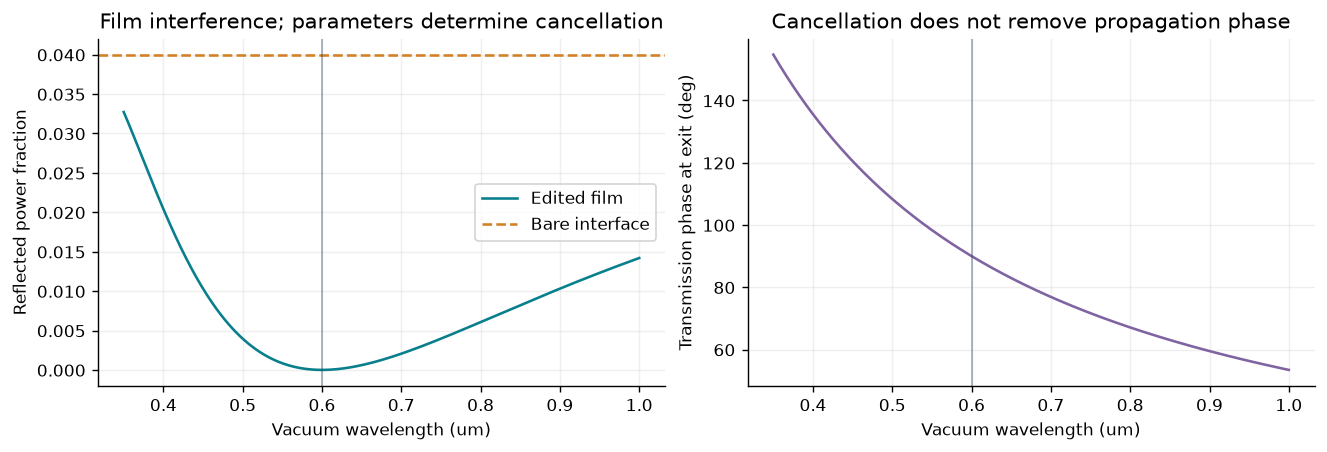

In [4]:
wavelengths=np.linspace(.35,1.,391)
film_spectrum=film(N_INCIDENT,N_FILM,N_OUTPUT,THICKNESS_UM,wavelengths)
film_reference=film(N_INCIDENT,N_FILM,N_OUTPUT,THICKNESS_UM,WAVELENGTH_UM)
bare=interface(N_INCIDENT,N_OUTPUT,0.,'TE')
table(['Case','r','t at exit','|t|^2','R','T'],[['Bare interface',ctext(bare['r']),ctext(bare['t']),float(abs(bare['t'])**2),float(bare['R']),float(bare['T'])],['Edited film',ctext(film_reference['r']),ctext(film_reference['t']),float(abs(film_reference['t'])**2),float(film_reference['R']),float(film_reference['T'])]])
fig,axes=plt.subplots(1,2,figsize=(10.5,3.5),layout='constrained')
axes[0].plot(wavelengths,film_spectrum['R'],color=TEAL,label='Edited film')
axes[0].axhline(float(bare['R']),color=ORANGE,ls='--',label='Bare interface')
axes[0].set(xlabel='Vacuum wavelength (um)',ylabel='Reflected power fraction',title='Film interference; parameters determine cancellation');axes[0].legend()
axes[1].plot(wavelengths,np.rad2deg(np.unwrap(np.angle(film_spectrum['t']))),color=PURPLE)
axes[1].set(xlabel='Vacuum wavelength (um)',ylabel='Transmission phase at exit (deg)',title='Cancellation does not remove propagation phase')
for ax in axes:ax.axvline(WAVELENGTH_UM,color=NAVY,alpha=.4,lw=1);ax.grid(alpha=.2)
plt.show()

## 4. Follow the electric-field tip

Use the unit Jones vector $J=(\cos\alpha,\sin\alpha e^{i\delta})^T$ at a fixed
point. With $e^{-i\omega t}$ the field tip is
$(\cos\alpha\cos\omega t,\sin\alpha\cos(\delta-\omega t))$.
Define $V=2\operatorname{Im}(E_x^*E_y)$ and report this coordinate convention
instead of assigning an ambiguous circular-handedness label.
A linear analyzer at $\beta$ transmits $|\cos\beta E_x+\sin\beta E_y|^2$.

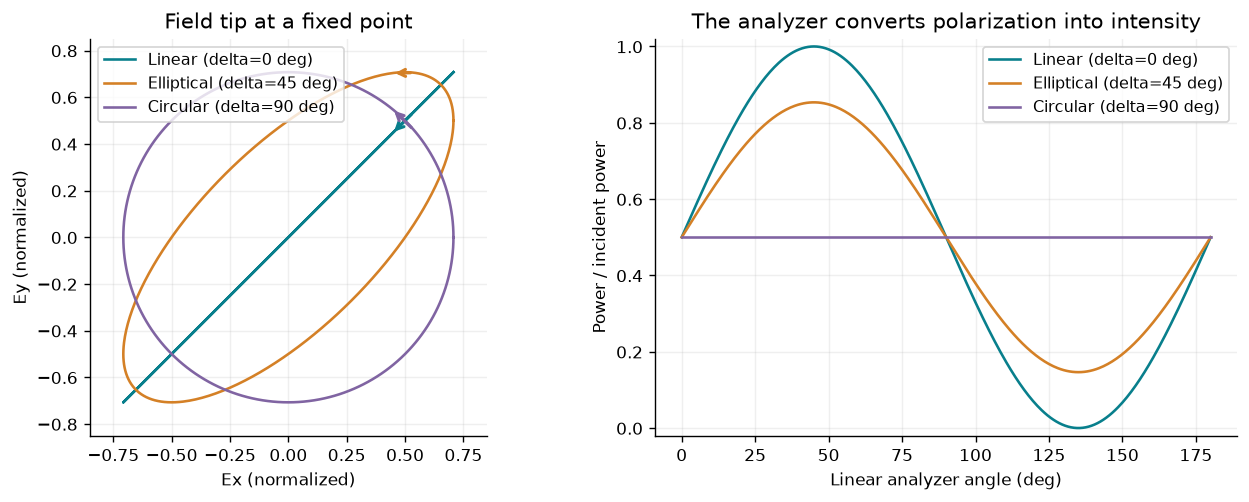

State at alpha=45 deg,I,Q,U,V,Power through x analyzer
Linear (delta=0 deg),1,0,1,0,0.5
Elliptical (delta=45 deg),1,-1.110223e-16,0.7071068,0.7071068,0.5
Circular (delta=90 deg),1,0,6.123234e-17,1,0.5


In [5]:
tau=np.linspace(0.,2*np.pi,401);betas=np.linspace(0.,180.,361)
fig,axes=plt.subplots(1,2,figsize=(10,3.9),layout='constrained');jones_cases=[]
for delta,color in [(0.,TEAL),(45.,ORANGE),(90.,PURPLE)]:
    V=np.sin(2*np.deg2rad(JONES_ALPHA_DEG))*np.sin(np.deg2rad(delta))
    name='Linear' if abs(V)<1e-12 else ('Circular' if abs(abs(V)-1)<1e-12 else 'Elliptical')
    name+=f' (delta={delta:g} deg)'
    J=polarization(JONES_ALPHA_DEG,delta,0.)
    ex=np.real(J['Ex']*np.exp(-1j*tau));ey=np.real(J['Ey']*np.exp(-1j*tau))
    axes[0].plot(ex,ey,color=color,label=name)
    j=45;axes[0].annotate('',xy=(ex[j+12],ey[j+12]),xytext=(ex[j],ey[j]),arrowprops=dict(arrowstyle='->',color=color,lw=1.8))
    transmission=polarization(JONES_ALPHA_DEG,delta,betas)['analyzer_power']
    axes[1].plot(betas,transmission,color=color,label=name)
    jones_cases.append(dict(name=name,alpha_deg=JONES_ALPHA_DEG,delta_deg=delta,response=J))
axes[0].set(xlabel='Ex (normalized)',ylabel='Ey (normalized)',title='Field tip at a fixed point',xlim=(-.85,.85),ylim=(-.85,.85));axes[0].set_aspect('equal')
axes[1].set(xlabel='Linear analyzer angle (deg)',ylabel='Power / incident power',title='The analyzer converts polarization into intensity',ylim=(-.02,1.02))
for ax in axes:ax.grid(alpha=.2);ax.legend(fontsize=9)
plt.show()
table([f'State at alpha={JONES_ALPHA_DEG:g} deg','I','Q','U','V','Power through x analyzer'],[[c['name']]+[float(c['response'][k]) for k in ['I','Q','U','V','analyzer_power']] for c in jones_cases])

## 5. Phase controls absorption

For a coincident-plane electric sheet in air, $g=\eta_0Y_s=G+iB$,
$r=-g/(2+g)$, $t=2/(2+g)$, and $A=G|t|^2$.
At $g=2$ one incident wave gives $R=T=1/4$ and $A=1/2$.
Two equal-power coherent inputs at the same **total** incident power instead give
$A_{2\mathrm{in}}=(1+\cos\phi)/2$. The field phases determine excitation of the
dissipative even channel or the nondissipative odd channel.

This is an ideal boundary-model result, not a fabricated absorber. The algebraic
retrieval $g=2(1-t)/t$ requires meaningful $t$ and the sheet constraint $t=1+r$.
It cannot be applied to a finite film's different reference planes indiscriminately.

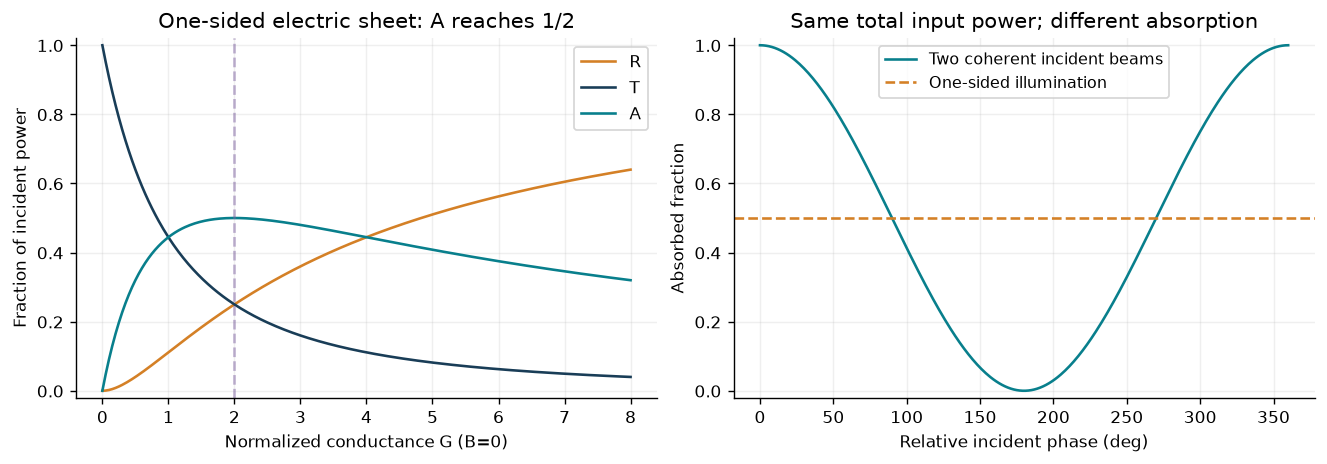

G,B,r,t,R,T,A,Retrieved g
0,0,0.00000+0.00000i,1.00000+0.00000i,0,1,0,0.00000+0.00000i
0,2,-0.50000-0.50000i,0.50000-0.50000i,0.5,0.5,0,0.00000+2.00000i
0.4,-1,-0.28994+0.29586i,0.71006+0.29586i,0.1715976,0.591716,0.2366864,0.40000-1.00000i
2,0,-0.50000+0.00000i,0.50000+0.00000i,0.25,0.25,0.5,2.00000+0.00000i
6,0,-0.75000+0.00000i,0.25000+0.00000i,0.5625,0.0625,0.375,6.00000+0.00000i


Relative phase (deg),Two-beam absorbed fraction
0,1
90,0.5
180,2.220446e-16
270,0.5


In [6]:
conductances=np.linspace(0.,8.,321);phases=np.linspace(0.,360.,361)
shunt_sweep=sheet(conductances,0.)
coherent_sweep=coherent_sheet(SHEET_G,SHEET_B,phases)
fig,axes=plt.subplots(1,2,figsize=(10.5,3.6),layout='constrained')
for key,color in [('R',ORANGE),('T',NAVY),('A',TEAL)]:axes[0].plot(conductances,shunt_sweep[key],color=color,label=key)
axes[0].axvline(2,color=PURPLE,ls='--',alpha=.5);axes[0].set(xlabel='Normalized conductance G (B=0)',ylabel='Fraction of incident power',title='One-sided electric sheet: A reaches 1/2');axes[0].legend()
axes[1].plot(phases,coherent_sweep['absorbed'],color=TEAL,label='Two coherent incident beams')
axes[1].axhline(float(sheet(SHEET_G,SHEET_B)['A']),color=ORANGE,ls='--',label='One-sided illumination')
axes[1].set(xlabel='Relative incident phase (deg)',ylabel='Absorbed fraction',title='Same total input power; different absorption');axes[1].legend(fontsize=9)
for ax in axes:ax.set_ylim(-.02,1.02);ax.grid(alpha=.2)
plt.show()
sheet_cases=[]
for G,B in [(0.,0.),(0.,2.),(.4,-1.),(2.,0.),(6.,0.)]:
    s=sheet(G,B);retrieved=retrieve_sheet(s['r'],s['t']);sheet_cases.append(dict(G=G,B=B,response=s,retrieved_g=retrieved))
table(['G','B','r','t','R','T','A','Retrieved g'],[[c['G'],c['B'],ctext(c['response']['r']),ctext(c['response']['t'])]+[float(c['response'][k]) for k in ['R','T','A']]+[ctext(c['retrieved_g'])] for c in sheet_cases])
table(['Relative phase (deg)','Two-beam absorbed fraction'],[[p,float(coherent_sheet(2.,0.,p)['absorbed'])] for p in [0.,90.,180.,270.]])

### A controlled retrieval-error experiment

The inverse is sensitive even when its analytical formula is exact. Sweep passive real shunts in equal air media and add a fixed absolute complex perturbation to transmission. Predict how the inferred parameter error changes as transmission becomes small.

$$
g(t+\delta t)-g(t)=-\frac{2\delta t}{t(t+\delta t)},\qquad
|\delta g|\approx\frac{2|\delta t|}{|t|^2}\quad (|\delta t|\ll|t|).
$$

The code compares the exact finite difference with the local derivative estimate. The estimate requires the perturbation to be small **relative to transmission**, not merely small relative to one. We set the perturbed reflection to the perturbed transmission minus one, so this is a model-consistent synthetic sensitivity experiment. Independent measurement errors in reflection and transmission can also violate continuity and must be checked separately; they are not silently forced into this inverse.

Edit the perturbation magnitude and direction below. Report the ratio of perturbation magnitude to transmission, identify where the linear estimate fails, and distinguish inferred parameters from the original passive sheet. All curves are original calculations from the stated inverse, with no measured or full-wave data.


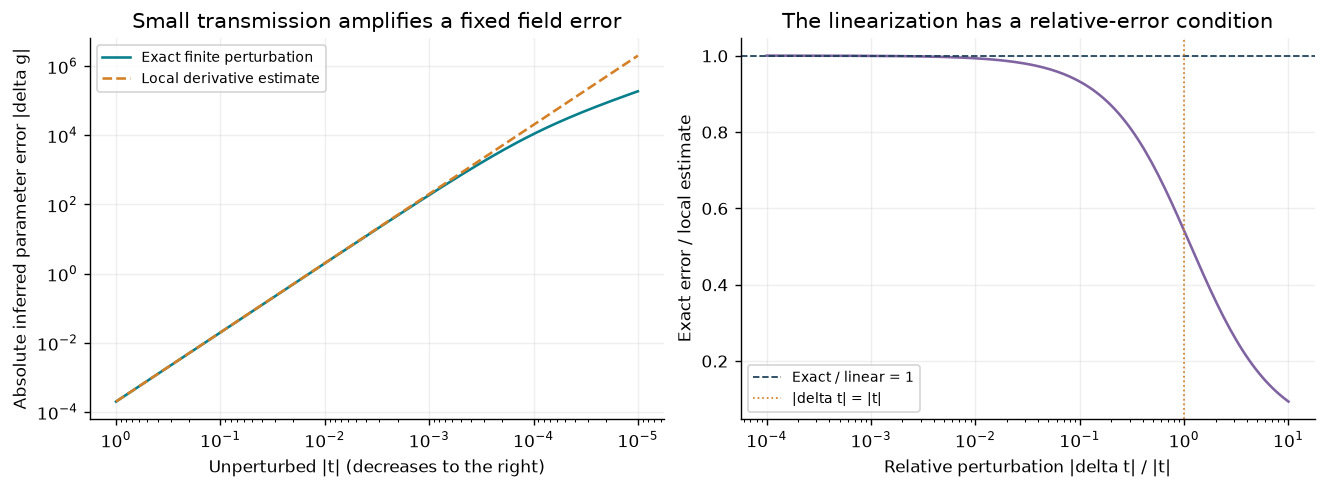

Unperturbed |t|,|delta t| / |t|,Exact |delta g|,Local estimate
1,0.0001,0.0001999859,0.0002
0.1,0.001,0.01998586,0.02
0.01,0.01,1.985908,2
0.001,0.1,186.3858,200
0.0001,1,10823.92,20000
1e-05,10,186385.8,2000000


Continuity residual if only transmission is perturbed: 0.00010000000000011169
The plotted inverse instead uses model-consistent perturbed r=t-1; independent measurement noise needs its own residual/tolerance model.


In [7]:
# A deterministic synthetic perturbation, not a measurement-noise distribution.
RETRIEVAL_PERTURBATION = 1e-4
RETRIEVAL_DIRECTION_DEG = 45.
RETRIEVAL_MIN_TRANSMISSION = 1e-5
assert 0 < RETRIEVAL_PERTURBATION < .01
assert 0 < RETRIEVAL_MIN_TRANSMISSION < 1
assert np.isfinite(RETRIEVAL_DIRECTION_DEG)

nominal_amplitudes = np.geomspace(1., RETRIEVAL_MIN_TRANSMISSION, 161)
nominal_conductances = 2/nominal_amplitudes-2
nominal_sheet = sheet(nominal_conductances, 0.)
nominal_t = nominal_sheet['t'].astype(complex)
delta_t = RETRIEVAL_PERTURBATION*np.exp(1j*np.deg2rad(RETRIEVAL_DIRECTION_DEG))
perturbed_t = nominal_t+delta_t
perturbed_r = perturbed_t-1  # Deliberately preserve this synthetic model's continuity.
assert np.all(np.abs(perturbed_t) > 1e-8), 'Choose a perturbation away from the inverse singularity.'
retrieved_perturbed = retrieve_sheet(perturbed_r, perturbed_t)
parameter_error = np.abs(retrieved_perturbed-nominal_conductances)
finite_difference = 2*abs(delta_t)/(np.abs(nominal_t)*np.abs(perturbed_t))
linear_estimate = 2*abs(delta_t)/np.abs(nominal_t)**2
relative_perturbation = abs(delta_t)/np.abs(nominal_t)
assert np.allclose(parameter_error, finite_difference, rtol=1e-8, atol=1e-9)
small_perturbation = relative_perturbation <= .01
assert np.max(np.abs(parameter_error[small_perturbation]/linear_estimate[small_perturbation]-1)) < .011

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8), layout='constrained')
axes[0].loglog(np.abs(nominal_t), parameter_error, color=TEAL, label='Exact finite perturbation')
axes[0].loglog(np.abs(nominal_t), linear_estimate, '--', color=ORANGE, label='Local derivative estimate')
axes[0].invert_xaxis()
axes[0].set(xlabel='Unperturbed |t| (decreases to the right)', ylabel='Absolute inferred parameter error |delta g|', title='Small transmission amplifies a fixed field error')
axes[1].semilogx(relative_perturbation, parameter_error/linear_estimate, color=PURPLE)
axes[1].axhline(1., color=NAVY, ls='--', lw=1, label='Exact / linear = 1')
axes[1].axvline(1., color=ORANGE, ls=':', lw=1, label='|delta t| = |t|')
axes[1].set(xlabel='Relative perturbation |delta t| / |t|', ylabel='Exact error / local estimate', title='The linearization has a relative-error condition')
for ax in axes:
    ax.grid(alpha=.2)
    ax.legend(fontsize=8)
plt.show()
selected_rows = np.linspace(0, len(nominal_t)-1, 6, dtype=int)
table(['Unperturbed |t|', '|delta t| / |t|', 'Exact |delta g|', 'Local estimate'],
      [[float(abs(nominal_t[j])), float(relative_perturbation[j]), float(parameter_error[j]), float(linear_estimate[j])] for j in selected_rows])
independent_continuity_residual = float(np.max(np.abs(perturbed_t-1-nominal_sheet['r'])))
print('Continuity residual if only transmission is perturbed:', independent_continuity_residual)
print('The plotted inverse instead uses model-consistent perturbed r=t-1; independent measurement noise needs its own residual/tolerance model.')
retrieval_conditioning = dict(perturbation_magnitude=RETRIEVAL_PERTURBATION,
    perturbation_direction_deg=RETRIEVAL_DIRECTION_DEG,
    nominal_t=nominal_t, nominal_g=nominal_conductances,
    perturbed_t=perturbed_t, perturbed_r=perturbed_r, retrieved_g=retrieved_perturbed,
    relative_perturbation=relative_perturbation, absolute_parameter_error=parameter_error,
    linear_estimate=linear_estimate, independent_continuity_residual=independent_continuity_residual,
    scope='Deterministic model-consistent sensitivity experiment; not measured noise or geometry retrieval')


## 6. Audit and export

For propagating ports, power-normalized amplitudes include $\sqrt{Y}$.
The lossless film matrix must be unitary and reciprocal. A dissipative sheet
must be contractive instead. These are checks of exact planar models; an
independent four-boundary-equation film solve and wider parameter audit are
provided by `scripts/validate_chapter02.py`.

The quarter-wave zero is tested on a fixed fixture. Edited films are checked for conservation and unitarity. Save notebook edits before running: exported data record the numerical code, parameters, and result-payload hashes. These identities detect changed artifacts; they do not replace independent scientific validation.


In [8]:
normal=interface(1.,1.5,0.,'TE')
assert abs(normal['r']+.2)<1e-12 and abs(normal['t']-.8)<1e-12
assert abs(normal['T']-.96)<1e-12
S=film_scattering(N_INCIDENT,N_FILM,N_OUTPUT,THICKNESS_UM,wavelengths)
film_unitarity=float(np.max(abs(np.swapaxes(S.conj(),-1,-2)@S-np.eye(2))))
assert film_unitarity<1e-12
assert abs(float(film_reference['R']+film_reference['T'])-1)<1e-12
# Independent fixed quarter-wave regression, not a constraint on edited thickness.
quarter_fixture=film(1.,np.sqrt(1.5),1.5,.6/(4*np.sqrt(1.5)),.6)
assert float(quarter_fixture['R'])<1e-12
assert abs(float(sheet(2.,0.)['A'])-.5)<1e-12
assert abs(float(coherent_sheet(2.,0.,0.)['absorbed'])-1)<1e-12
assert abs(float(coherent_sheet(2.,0.,180.)['absorbed']))<1e-12
j=polarization(35.,61.,17.)
stokes_error=float(abs(j['I']**2-j['Q']**2-j['U']**2-j['V']**2));assert stokes_error<1e-12
def serial(value):
    if isinstance(value,dict):return {k:serial(v) for k,v in value.items()}
    if isinstance(value,(list,tuple)):return [serial(v) for v in value]
    if isinstance(value,np.ndarray):return serial(value.tolist())
    if isinstance(value,(complex,np.complexfloating)):return dict(re=serial(float(value.real)),im=serial(float(value.imag)))
    if isinstance(value,(float,np.floating)):return float(value) if np.isfinite(value) else None
    if isinstance(value,np.generic):return value.item()
    return value
metadata=dict(model_version=MODEL_VERSION,topic_ids=['ms-01-waves-interfaces','ms-03-sheet-response','ms-06-polarization'],source_sha256=hashlib.sha256((ROOT/'simulations/waves_interfaces.py').read_bytes()).hexdigest(),model='exact planar interface/film/electric-sheet and Jones models',time_convention='exp(-i omega t)',spatial_convention='exp(+i k.r)',amplitude_basis='common tangential electric field; reflected TM sign differs from a rotating local p basis',phase_planes=dict(interface='z=0',sheet='coincident sheet plane',film='entrance for r; exit for t'),bulk_model='positive real constant refractive indices, isotropic nonmagnetic media',limitations=['No patterned-geometry Maxwell solver','No measured dispersion or fabricated-device validation','Film and sheet at normal incidence','Jones analyzer is an ideal deterministic fully polarized model','Electric-sheet retrieval is algebra under explicit continuity and plane assumptions'],environment=dict(python=platform.python_version(),numpy=np.__version__,matplotlib=matplotlib.__version__))
data=dict(metadata=metadata,parameters=dict(n1=N_INCIDENT,n2=N_OUTPUT,nf=N_FILM,wavelength_um=WAVELENGTH_UM,thickness_um=THICKNESS_UM),interface_cases=interface_cases,angles_deg=ANGLES_DEG,angular=angular,field_checks=field_checks,film_benchmark=film_reference,wavelengths_um=wavelengths,film_spectrum=film_spectrum,jones_cases=jones_cases,sheet_cases=sheet_cases,conductances=conductances,sheet_sweep=shunt_sweep,relative_phases_deg=phases,coherent_sweep=coherent_sweep,retrieval_conditioning=retrieval_conditioning,checks=dict(film_unitarity_error=film_unitarity,stokes_error=stokes_error))
data['parameters'].update(field_n1=FIELD_N1,field_n2=FIELD_N2,field_angle_deg=FIELD_ANGLE_DEG,
    jones_alpha_deg=JONES_ALPHA_DEG,sheet_G=SHEET_G,sheet_B=SHEET_B,
    retrieval_perturbation=RETRIEVAL_PERTURBATION,retrieval_min_transmission=RETRIEVAL_MIN_TRANSMISSION,
    retrieval_direction_deg=RETRIEVAL_DIRECTION_DEG)
assert notebook_code_sha256(NOTEBOOK_PATH)==CODE_SHA256, 'Notebook code changed during execution; save and restart.'
data=serial(data)
data['metadata']['notebook_code_sha256']=CODE_SHA256
data['metadata']['parameters_sha256']=json_sha256(data['parameters'])
data['metadata']['result_payload_sha256']=result_sha256(data)
(DATA/'waves-reference.json').write_text(json.dumps(data,indent=2,allow_nan=False)+'\n',encoding='utf-8')
with (DATA/'waves-reference.csv').open('w',newline='',encoding='utf-8') as handle:
    writer=csv.writer(handle);writer.writerow(['experiment','parameter','value','r_real','r_imag','t_real','t_imag','R','T','A','phase_deg'])
    def row(name,key,value,v,j):
        phase=float(v['phase_deg'][j]);writer.writerow([name,key,float(value),float(v['r'][j].real),float(v['r'][j].imag),float(v['t'][j].real),float(v['t'][j].imag),float(v['R'][j]),float(v['T'][j]),float(v.get('A',np.zeros_like(v['R']))[j]),'' if not np.isfinite(phase) else phase])
    for name,v in angular.items():
        for j,a in enumerate(ANGLES_DEG):row(name,'angle_deg',a,v,j)
    for j,w in enumerate(wavelengths):row('edited_film','wavelength_um',w,film_spectrum,j)
    for j,G in enumerate(conductances):row('electric_sheet_B0','conductance',G,shunt_sweep,j)
table(['Notebook check','Worst error'],[['Film power-normalized unitarity',film_unitarity],['Jones Stokes identity',stokes_error],['Transmitted flux error',field_checks['max_transmitted_flux_error']]])
print('Saved strict JSON and CSV with source hash and explicit reference-plane/model conventions.')

Notebook check,Worst error
Film power-normalized unitarity,8.881784e-16
Jones Stokes identity,2.220446e-16
Transmitted flux error,1.610571e-16


Saved strict JSON and CSV with source hash and explicit reference-plane/model conventions.


## Explain the surprises

Compare field amplitude with normal power, zero tangential amplitude with a
nonzero evanescent field, and one-sided with two-sided illumination. Explain
why quarter-wave antireflection is a spectral/reference-plane statement and why
sheet retrieval is a model test before it is an algebraic calculation.

See the [Chapter 2 derivations](../chapters/02-waves-and-interfaces.md),
[worked examples](../chapters/02-waves-guide.md), and
[lab](../labs/02-waves-lab.md). Extend this baseline to the existing Chapter 3
ridge and Chapter 4 diffraction investigations only after stating the additional
geometry, polarization, channels, phase planes, and numerical validation.